# PyTorch 입문 — 보스턴 집값 · MLP · DataLoader

CSV에서 특징·집값을 나누고, `MinMaxScaler` · MLP(`13→64→32→1`) · `DataLoader`로 학습한 뒤 테스트 MSE·R²·산점도를 봅니다.  
이론 복습: [`../session09.md`](../session09.md)

> **이 노트북이 하는 일**  
> CSV → train/test → 스케일(fit=train만) → 텐서 → `LinearReg` · ReLU → SGD · 배치 학습 → 테스트 MSE · R² · 산점도(가로=실제, 세로=예측).

환경: `torch-env` 커널을 쓰는 것을 권장합니다. `pandas` · `scikit-learn`이 필요합니다.

## 1. import

In [13]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim # 데이터를 최적화하는 함수
import pandas as pd
from sklearn.model_selection import train_test_split # 데이터를 훈련 데이터와 테스트 데이터로 나누는 함수
from sklearn.preprocessing import MinMaxScaler # 데이터를 0과 1 사이의 값으로 정규화하는 함수
from sklearn.metrics import r2_score # 데이터의 성능을 측정하는 함수
from torch.utils.data import TensorDataset, DataLoader # 데이터를 텐서로 변환하는 함수

## 2. CSV 로드 · feature · target

경로는 노트북 기준 상대경로 `data/boston_house.csv`입니다.  
`MEDV`는 집값(정답), `Unnamed: 0`은 학습에 쓰지 않습니다.

In [14]:
df = pd.read_csv("data/boston_house.csv")
feature = df.drop(["MEDV", "Unnamed: 0"], axis=1) # MEDV와 Unnamed: 0 열을 제외한 모든 열을 feature로 설정
target = df.pop("MEDV") # MEDV 열을 target으로 설정

X = feature.to_numpy()
y = target.values # target을 넘파이 배열로 변환
print(X.shape, y.shape) # (506, 13), (506, 1)
# 2차원 배열 데이터 이므로, sum 을 두 번 사용
print("feature 결측:", feature.isna().sum().sum()) # feature 결측: 0
print("target 결측:", target.isna().sum()) # target 결측: 0

(506, 13) (506,)
feature 결측: 0
target 결측: 0


## 3. train / test 나누기

테스트는 학습에 안 쓴 점수표입니다.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1 # test_size=0.2: 20%를 테스트 데이터로 사용, random_state=1: 랜덤 시드 설정
)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape) # (404, 13), (102, 13), (404, ), (102, )

(404, 13) (102, 13) (404,) (102,)


## 4. MinMaxScaler — fit은 train만

각 열을 0~1로 압축합니다. 예: `[10, 20, 30, 40, 100]` → `(값-10)/(100-10)` → `0 ~ 1`.  
테스트에 `fit`을 하면 테스트 최솟값·최댓값이 학습 전처리에 섞입니다(데이터 누수).

In [16]:
mc = MinMaxScaler()
X_train = mc.fit_transform(X_train)  # 학습에서만 최솟값·최댓값 기억
X_test = mc.transform(X_test)  # 테스트는 transform만 (fit 금지)

## 5. 텐서 · `view(-1, 1)`

정답 열 수를 모델 출력 1개와 맞춥니다. `view(-1, 1)`은 "행은 알아서, 열은 1개"입니다.

In [17]:
X_train_tensor = torch.FloatTensor(X_train) # X_train을 텐서로 변환
X_test_tensor = torch.FloatTensor(X_test) # X_test을 텐서로 변환
y_train_tensor = torch.FloatTensor(y_train).view(-1, 1) # y_train을 텐서로 변환, view(-1, 1)은 "행은 알아서, 열은 1개"입니다.
y_test_tensor = torch.FloatTensor(y_test).view(-1, 1) # y_test을 텐서로 변환, view(-1, 1)은 "행은 알아서, 열은 1개"입니다.

print(X_train_tensor.shape, y_train_tensor.shape) # torch.Size([404, 13]) torch.Size([404, 1])
print(X_test_tensor.shape, y_test_tensor.shape) # torch.Size([102, 13]) torch.Size([102, 1])

torch.Size([404, 13]) torch.Size([404, 1])
torch.Size([102, 13]) torch.Size([102, 1])


## 6. MLP — `LinearReg` · 13→64→32→1 · ReLU

쉬운 비유: 특징 13개를 **64개 조합**으로 섞고, 겹치는 것을 줄여 **32개**로 압축한 뒤 **집값 1개**를 냅니다.  
은닉층에는 ReLU, 마지막 출력층에는 활성화 없이 집값 하나를 냅니다.

In [18]:
class LinearReg(nn.Module):
    def __init__(self, input_size, output_size):
        super().__init__()
        self.fc1 = nn.Linear(input_size, 64)  # 13 → 64: 특징을 여러 조합으로 펼침
        self.fc2 = nn.Linear(64, 32)  # 64 → 32: 겹치는 느낌 줄이며 압축
        self.fc3 = nn.Linear(32, output_size)  # 32 → 1: 집값

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        output = self.fc3(x)  # 마지막은 ReLU 없음(집값은 음수도 가능)
        return output

In [19]:
model = LinearReg(X_train.shape[1], 1)
print(model)
# LinearReg(
#  (fc1): Linear(in_features=13, out_features=64, bias=True)
#  (fc2): Linear(in_features=64, out_features=32, bias=True)
#  (fc3): Linear(in_features=32, out_features=1, bias=True)
#)

criterion = nn.MSELoss() # 평균 제곱 오차 함수
# lr: 한 번에 weight·bias를 얼마나 크게 고칠지. momentum: 이전 방향을 조금 기억
optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.5) # lr: 학습률, momentum: 이전 방향을 조금 기억
print(optimizer)
# SGD (
# Parameter Group 0
#     dampening: 0
#     density: 0
#     foreach: None
#     lr: 0.001
#     maximize: False
#     momentum: 0.5
#     nesterov: False
#     weight_decay: 0.0
# )

LinearReg(
  (fc1): Linear(in_features=13, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
)
SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    momentum: 0.5
    nesterov: False
    weight_decay: 0
)


## 7. TensorDataset · DataLoader

`TensorDataset`은 **같은 집의 특징·집값**을 한 묶음으로 맞춥니다.  
한 번에 32개씩, epoch마다 순서를 섞습니다(약 404÷32≈13 배치).

In [20]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

print(len(train_dataset), len(train_loader)) # 404 13

404 13


## 8. 학습 루프

배치마다 `zero_grad` → `backward` → `step` 순서를 지킵니다.

In [21]:
epochs = 100

for epoch in range(epochs):
    model.train() # 모델을 학습 모드로 설정
    running_loss = 0.0 # 이전 배치의 손실을 누적

    for x_batch, y_batch in train_loader:
        yhat = model(x_batch) # 모델에 x_batch를 입력하여 예측값을 계산
        loss = criterion(yhat, y_batch) # 예측값과 실제값의 차이를 계산

        optimizer.zero_grad()  # 이전 기울기 비우기
        loss.backward() # 손실을 미분하여 기울기를 계산
        optimizer.step()  # weight · bias 갱신(가중치와 편향을 업데이트)

        running_loss += loss.item() # 이전 배치의 손실을 누적

    if epoch % 20 == 0 or epoch == epochs - 1:
        avg_loss = running_loss / len(train_loader) # 이전 배치의 손실을 평균
        print(f"epoch {epoch:3d} | train_mse={avg_loss:.4f}")

epoch   0 | train_mse=518.4175
epoch  20 | train_mse=21.4913
epoch  40 | train_mse=16.4567
epoch  60 | train_mse=15.5392
epoch  80 | train_mse=12.2016
epoch  99 | train_mse=12.8951


## 9. 테스트 MSE · R² · 산점도

`eval` · `no_grad`로 기울기 없이 테스트 점수를 봅니다.  
R²(`r2_score`)는 평균만 찍는 것보다 얼마나 잘 맞췄는지입니다(1에 가까울수록 좋음).  
산점도: 가로=실제, 세로=예측. 파란 `y=x` 선에 점이 가까울수록 잘 맞춘 것입니다.

In [25]:
model.eval() # 모델을 테스트 모드로 설정
with torch.no_grad(): # 기울기 없이 테스트 점수를 계산
    y_pred = model(X_test_tensor) # 모델에 X_test_tensor를 입력하여 예측값을 계산
    test_mse = criterion(y_pred, y_test_tensor) # 예측값과 실제값의 차이를 계산

y_true_np = y_test_tensor.numpy().ravel() # y_test_tensor를 넘파이 배열로 변환하고, ravel()은 1차원 배열로 변환하는 함수
y_pred_np = y_pred.numpy().ravel()
test_r2 = r2_score(y_true_np, y_pred_np)

print("테스트 MSE:", test_mse.item()) # 테스트 MSE: 11.34965991973877
print("테스트 R2:", test_r2) # 테스트 R2: 0.8851567506790161

테스트 MSE: 11.34965991973877
테스트 R2: 0.8851567506790161


c:\Users\dmsrh\miniconda3\envs\torch-env\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\dmsrh\miniconda3\envs\torch-env\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\dmsrh\miniconda3\envs\torch-env\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\dmsrh\miniconda3\envs\torch-env\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


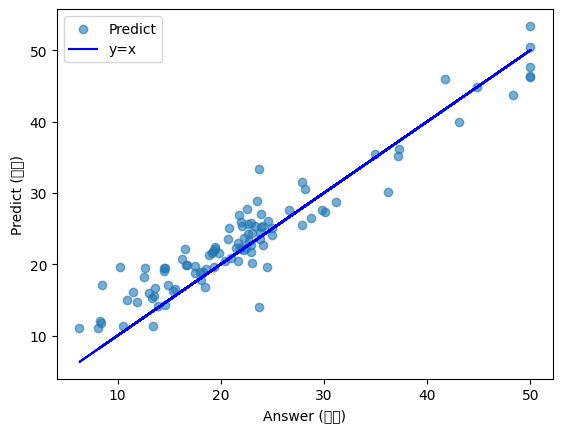

In [26]:
# 가로=실제, 세로=예측. 파란 선은 완벽히 맞춘 y=x
plt.scatter(y_true_np, y_pred_np, alpha=0.6, label="Predict")
plt.plot(y_true_np, y_true_np, color="blue", label="y=x")
plt.xlabel("Answer (실제)")
plt.ylabel("Predict (예측)")
plt.legend()
plt.show()

---

이론 복습: [`../session09.md`](../session09.md) · 다음: [`../session10.md`](../session10.md) · 이전 실습: [`09_multi_output_linear.ipynb`](./09_multi_output_linear.ipynb)